In [1]:
import pyvista as pv
from matplotlib import pyplot as plt
reader = pv.POpenFOAMReader('/WORK_OF/skota/tripleflame/tfclsp0.5/foam.foam') # path to foam file
reader.case_type='reconstructed' #use 'decomposed' for decomposed cases
reader.set_active_time_value(0.05) #give a correct time value
fields = reader.read()['internalMesh']
fields
line = fields.sample_over_line((0.005,0,0),(0.005,0.015,0),resolution=100) # point one, point 2
line

PolyData (0x7fd508e979a0)
  N Cells:    1
  N Points:   101
  N Strips:   0
  X Bounds:   5.000e-03, 5.000e-03
  Y Bounds:   0.000e+00, 1.500e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   33

In [2]:
print(line.points)
print(line.points[:,1])
print(line.points[:,2])


[[0.005   0.      0.     ]
 [0.005   0.00015 0.     ]
 [0.005   0.0003  0.     ]
 [0.005   0.00045 0.     ]
 [0.005   0.0006  0.     ]
 [0.005   0.00075 0.     ]
 [0.005   0.0009  0.     ]
 [0.005   0.00105 0.     ]
 [0.005   0.0012  0.     ]
 [0.005   0.00135 0.     ]
 [0.005   0.0015  0.     ]
 [0.005   0.00165 0.     ]
 [0.005   0.0018  0.     ]
 [0.005   0.00195 0.     ]
 [0.005   0.0021  0.     ]
 [0.005   0.00225 0.     ]
 [0.005   0.0024  0.     ]
 [0.005   0.00255 0.     ]
 [0.005   0.0027  0.     ]
 [0.005   0.00285 0.     ]
 [0.005   0.003   0.     ]
 [0.005   0.00315 0.     ]
 [0.005   0.0033  0.     ]
 [0.005   0.00345 0.     ]
 [0.005   0.0036  0.     ]
 [0.005   0.00375 0.     ]
 [0.005   0.0039  0.     ]
 [0.005   0.00405 0.     ]
 [0.005   0.0042  0.     ]
 [0.005   0.00435 0.     ]
 [0.005   0.0045  0.     ]
 [0.005   0.00465 0.     ]
 [0.005   0.0048  0.     ]
 [0.005   0.00495 0.     ]
 [0.005   0.0051  0.     ]
 [0.005   0.00525 0.     ]
 [0.005   0.0054  0.     ]
 

PolyData (0x7fd508a1f340)
  N Cells:    30000
  N Points:   30351
  N Strips:   0
  X Bounds:   0.000e+00, 2.000e-02
  Y Bounds:   0.000e+00, 1.500e-02
  Z Bounds:   0.000e+00, 0.000e+00
  N Arrays:   56

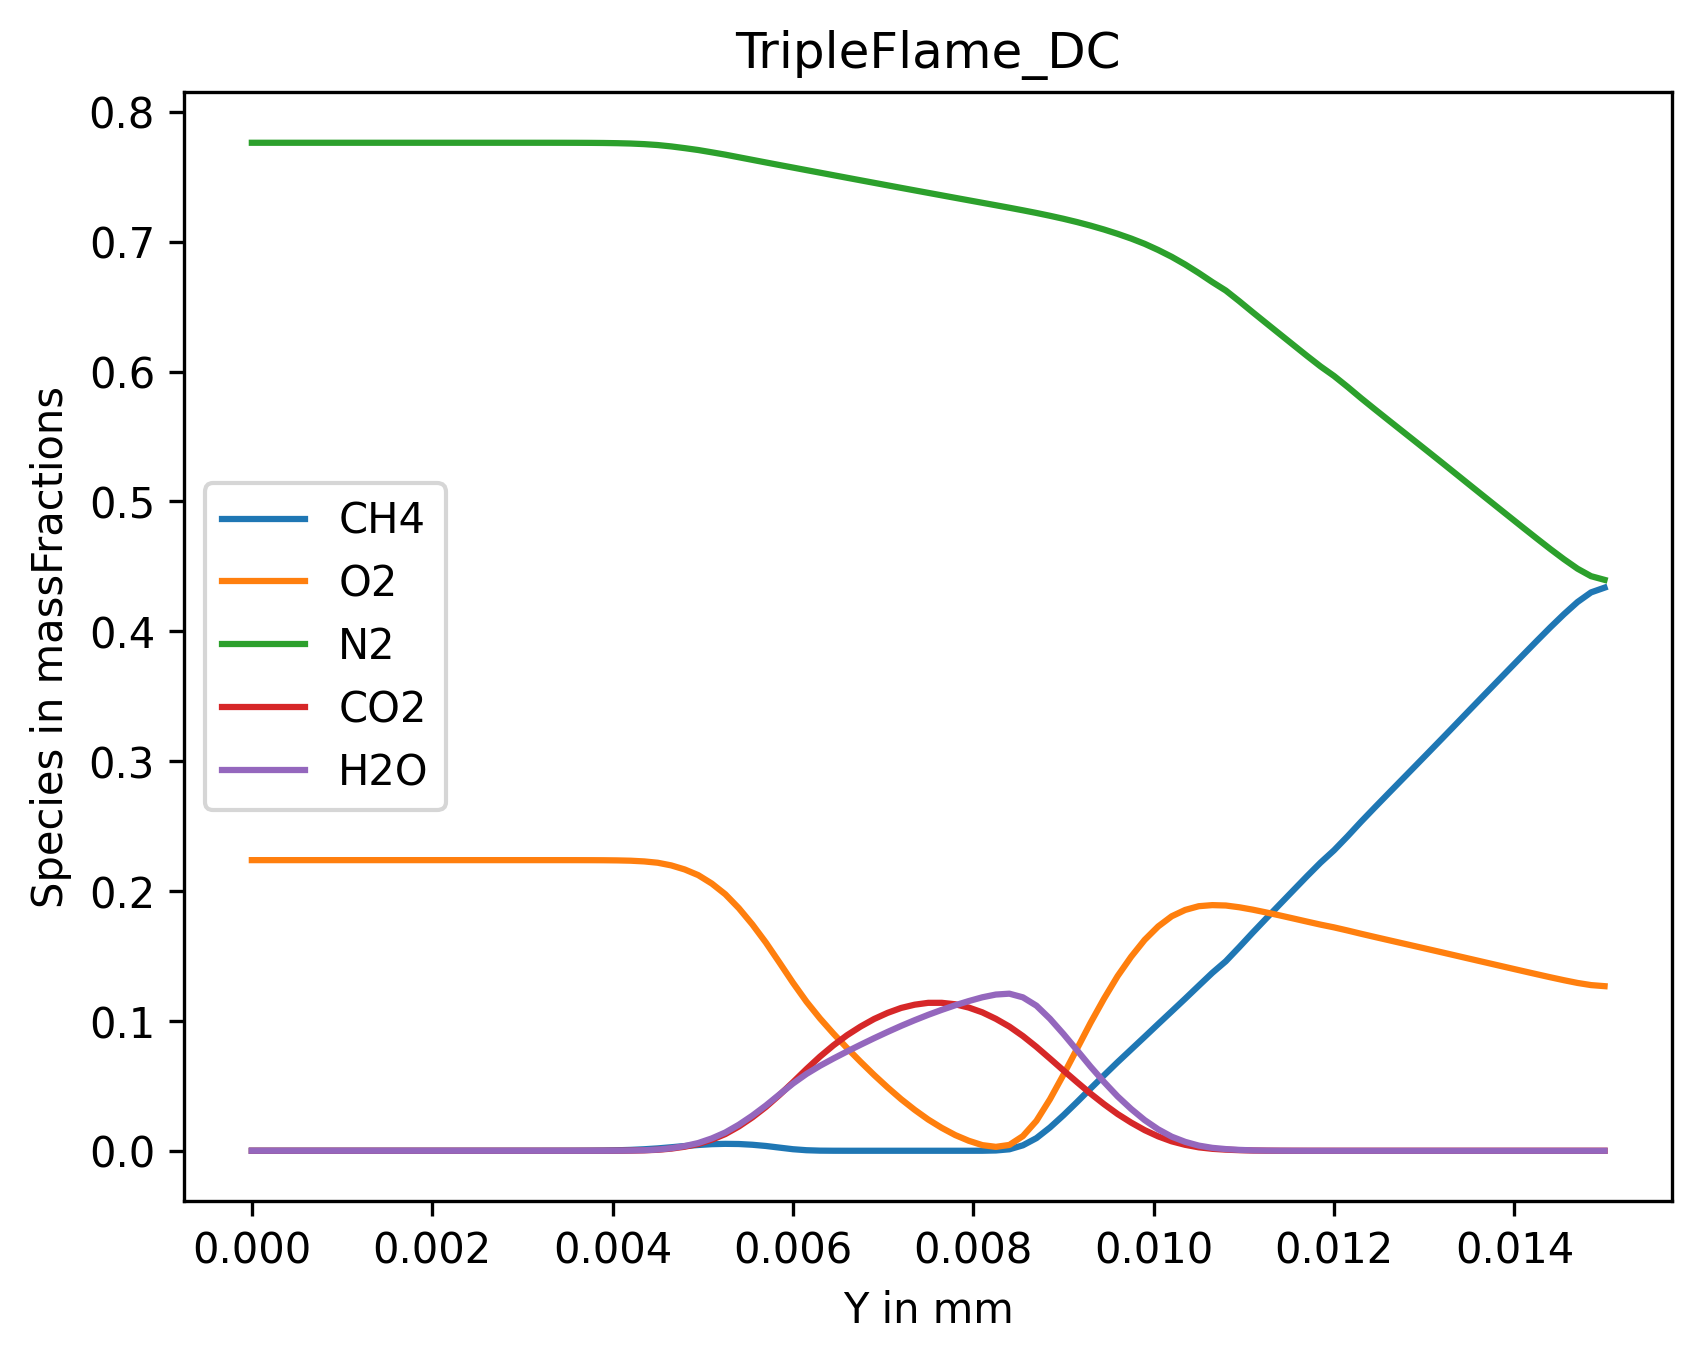

In [3]:
fig, ax = plt.subplots()
fig.set_dpi(300)
ax.plot(line.points[:,1],line['CH4'],label='CH4')
ax.plot(line.points[:,1],line['O2'],label='O2')
ax.plot(line.points[:,1],line['N2'],label='N2')
ax.plot(line.points[:,1],line['CO2'],label='CO2')
ax.plot(line.points[:,1],line['H2O'],label='H2O')
ax.set_xlabel('Y in mm')
ax.set_ylabel('Species in massFractions')
ax.set_title('TripleFlame_DC')
ax.legend()
slice = fields.slice((0,0,1),(0,0,0)) # origin vector, normal vector
slice

/tmp/ipykernel_24493/3654934239.py:12: UserWarning: The following kwargs were not used by contour: 'triangles'
  tricont = ax.tricontourf(pts[:,0], pts[:,1],  # pts X and Y in 2 D plot, depends on orientation of slice, for normal vector (0,0,1) use pts[:,0], pts[:,1]; for (0,1,0) use pts[:,0],pts[:,2]; (1,0,0) use pts[:,1],pts[:,2]


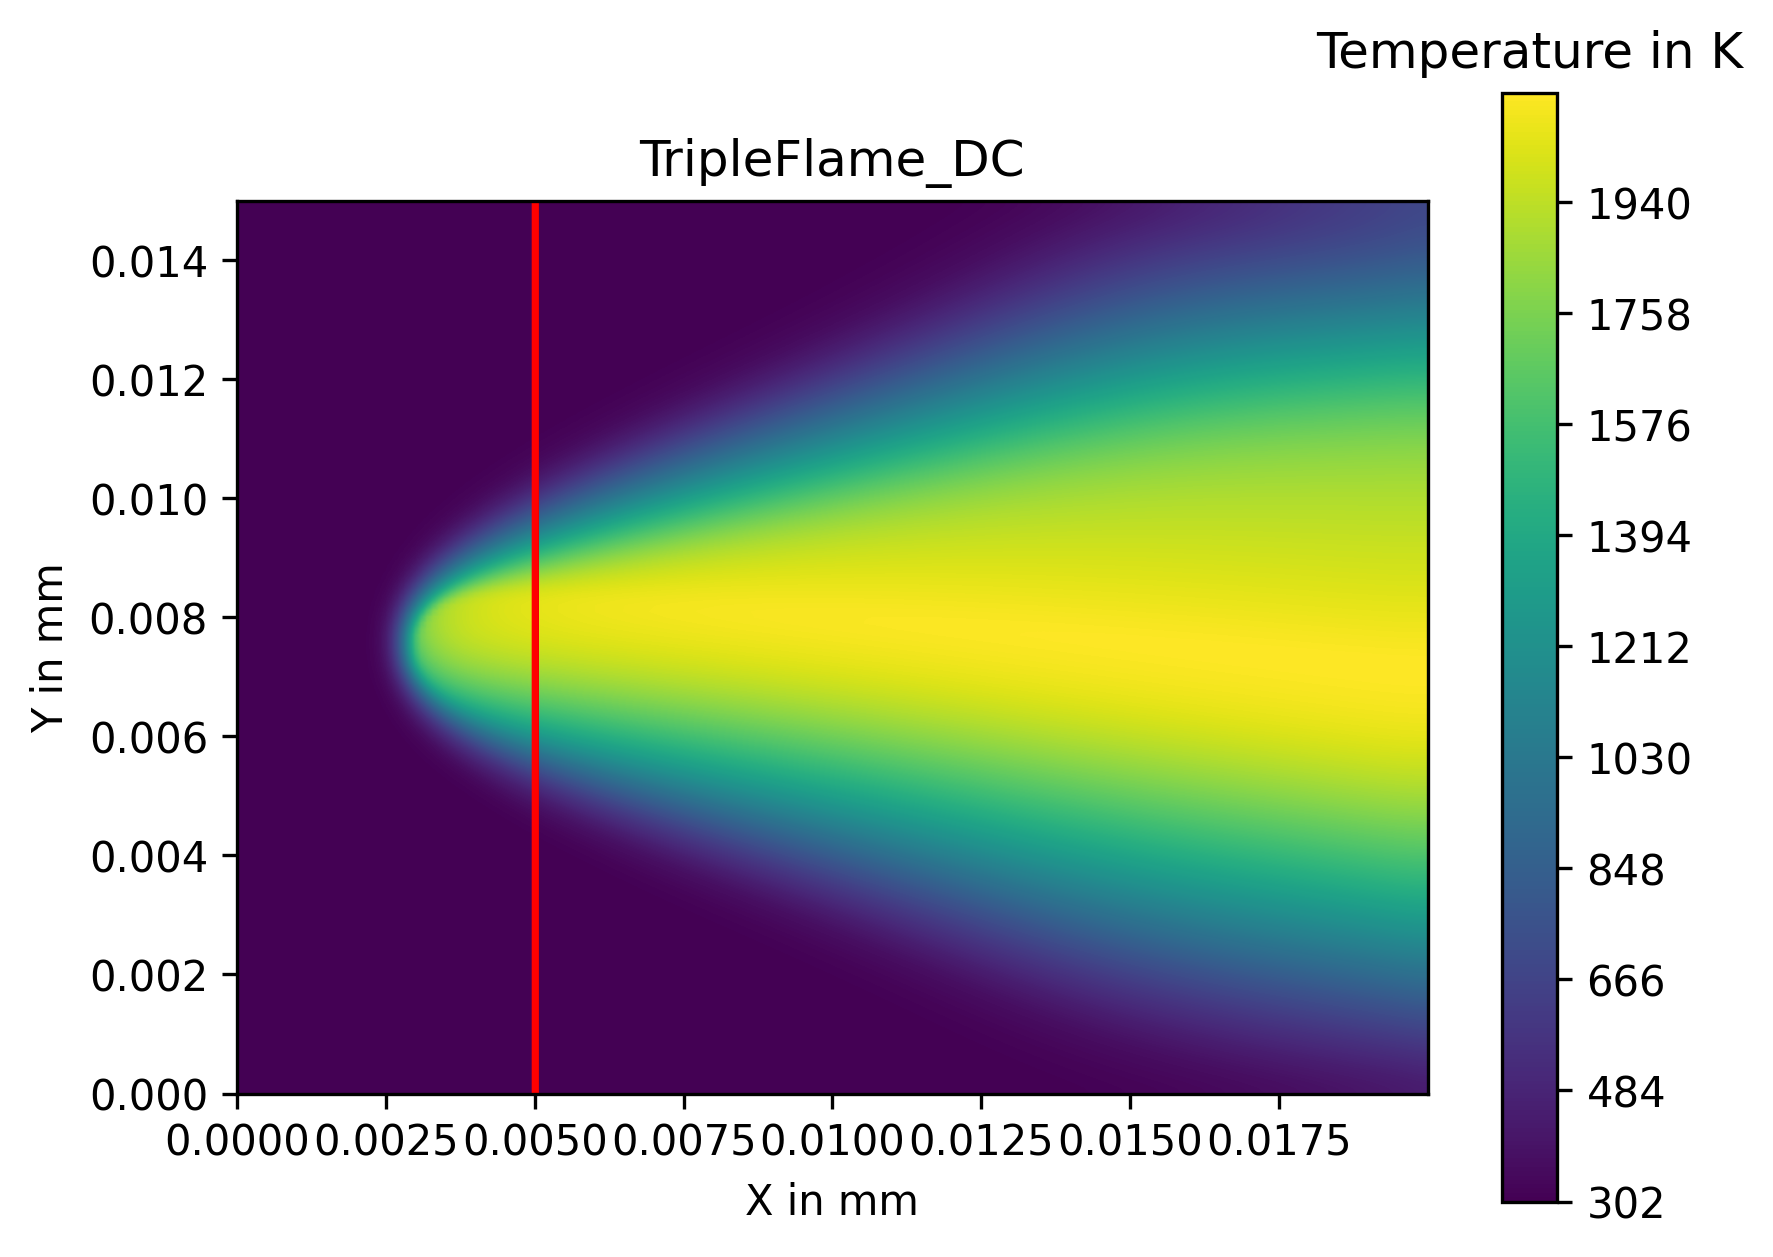

In [4]:
fig, ax = plt.subplots()
fig.set_dpi(300)
# prepare for plotting
plt_slice = slice.cell_data_to_point_data()
plt_slice = plt_slice.triangulate()
# get points, triangles, and values for plotting
pts = plt_slice.points
tri = plt_slice.faces.reshape((-1,4))[:,1:]
 # here you need to pick the field you want to plot (here vector y-coordinate x: 0, y: 1, z: 2)
val = plt_slice['T']
# val = plt_slice['p'] # scalar
tricont = ax.tricontourf(pts[:,0], pts[:,1],  # pts X and Y in 2 D plot, depends on orientation of slice, for normal vector (0,0,1) use pts[:,0], pts[:,1]; for (0,1,0) use pts[:,0],pts[:,2]; (1,0,0) use pts[:,1],pts[:,2]
                    val,
                    triangles=tri, 
                    levels=1000,
                    )
ax.set_aspect('equal')
ax.set_xlabel('X in mm')
ax.set_ylabel('Y in mm')
ax.set_title('TripleFlame_DC')
cb = fig.colorbar(tricont)
cb.ax.set_title(label='Temperature in K')
line = fields.sample_over_line((0.005, 0, 0), (0.005, 0.015, 0))
ax.plot(line.points[:, 0], line.points[:, 1], marker='o', color='red', markersize=0.25, linestyle='-')